<a href="https://colab.research.google.com/github/SECKidrissa/TER_M1_2025/blob/main/Bienvenue_dans_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df=sns.load_dataset('penguins')
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [28]:
df.isnull().sum()

,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11


In [29]:
print(df['species'].value_counts)

<bound method IndexOpsMixin.value_counts of 0      Adelie
1      Adelie
2      Adelie
3      Adelie
4      Adelie
        ...  
339    Gentoo
340    Gentoo
341    Gentoo
342    Gentoo
343    Gentoo
Name: species, Length: 344, dtype: object>


In [30]:
df.groupby('species').mean(numeric_only=True).round(1)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.8,18.3,190.0,3700.7
Chinstrap,48.8,18.4,195.8,3733.1
Gentoo,47.5,15.0,217.2,5076.0


<function matplotlib.pyplot.show(close=None, block=None)>

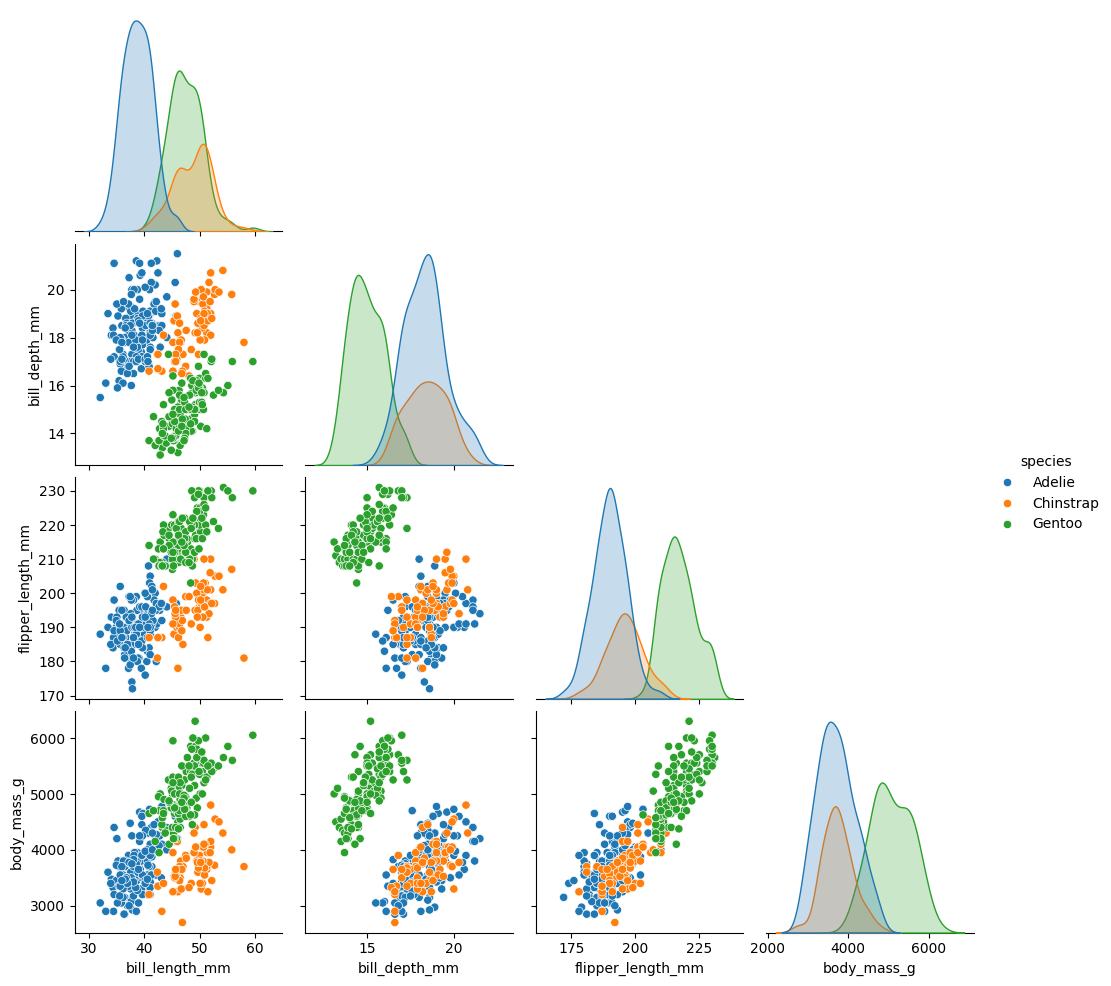

In [31]:
sns.pairplot(df,hue='species' , corner= True)
plt.show

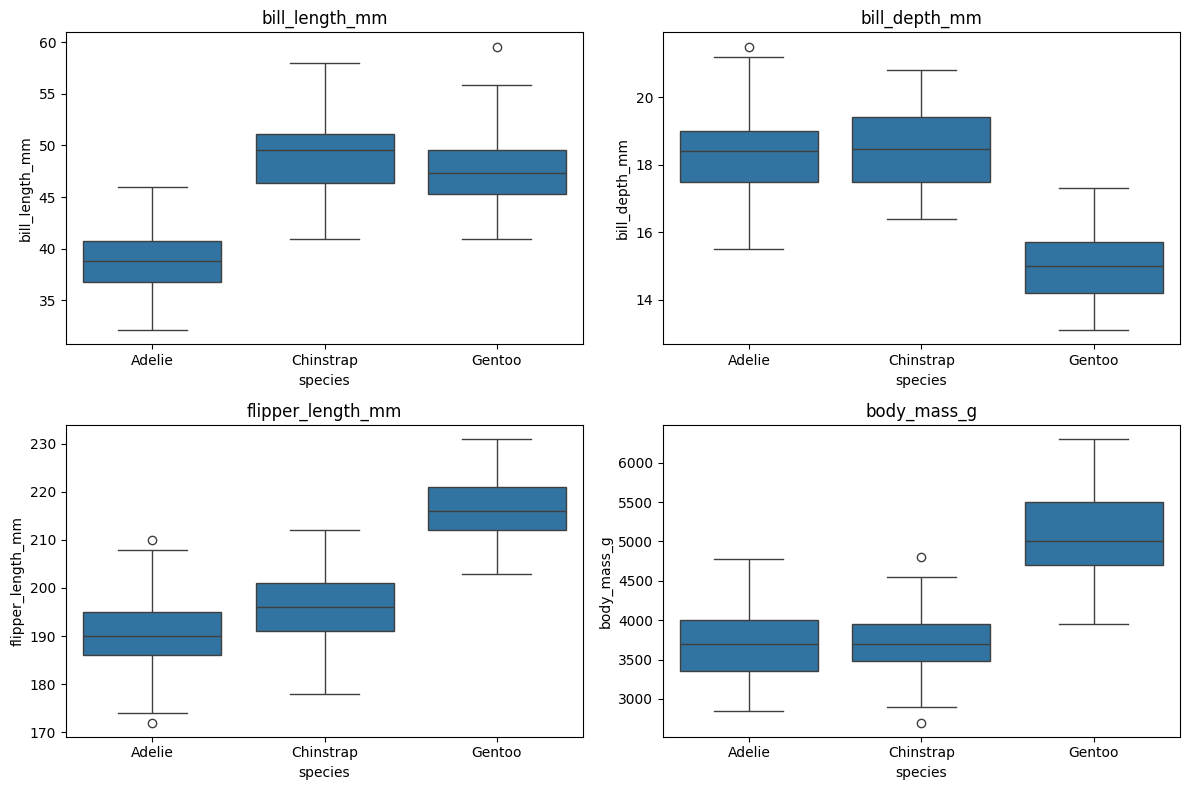

In [32]:
mesures = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flatten(), mesures):   # .flatten() : grille 2x2 -> liste de 4
    sns.boxplot(data=df, x="species", y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [35]:
print(pd.crosstab(df["island"], df["species"]))
print(pd.crosstab(df["sex"], df["species"]))

species    Adelie  Chinstrap  Gentoo
island                              
Biscoe         44          0     124
Dream          56         68       0
Torgersen      52          0       0
species  Adelie  Chinstrap  Gentoo
sex                               
Female       73         34      58
Male         73         34      61


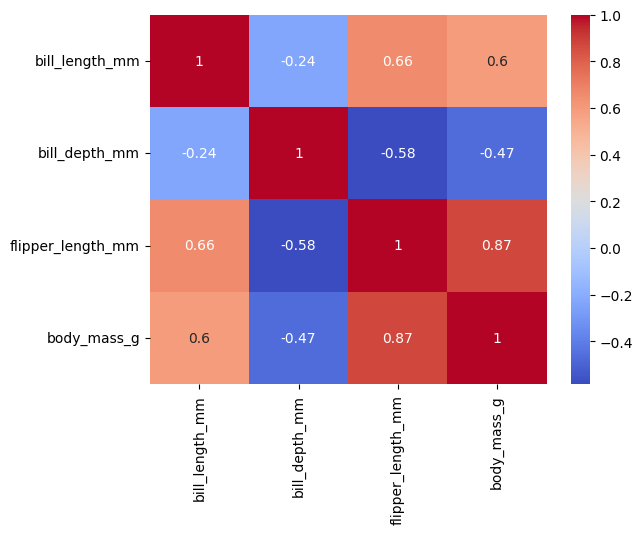

In [36]:
sns.heatmap(df[ mesures].corr(), annot=True, cmap="coolwarm")
plt.show()


In [43]:
from re import X
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
num= ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
cat= ['sex']
x= df[ num + cat]
y= df['species']

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2 , stratify=y, random_state=42)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)
print(y_test.value_counts(normalize=True).round(2))


(275, 5) (69, 5) (275,) (69,)
species
Adelie       0.43
Gentoo       0.36
Chinstrap    0.20
Name: proportion, dtype: float64


In [42]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

prepa = ColumnTransformer([
    ("num", Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler()),
    ]), num),
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("oh", OneHotEncoder(handle_unknown="ignore")),
    ]), cat),
])

X_train_prep = prepa.fit_transform(X_train)   # fit = apprendre sur le train
X_test_prep = prepa.transform(X_test)         # transform seulement sur le test

print(X_train_prep.shape)
print(prepa.get_feature_names_out())
print(prepa.named_transformers_["num"].named_steps["imp"].statistics_)
pd.DataFrame(X_train_prep, columns=prepa.get_feature_names_out()).describe().round(2)

(275, 6)
['num__bill_length_mm' 'num__bill_depth_mm' 'num__flipper_length_mm'
 'num__body_mass_g' 'cat__sex_Female' 'cat__sex_Male']
[  44.9   17.3  197.  4050. ]


,num__bill_length_mm,num__bill_depth_mm,num__flipper_length_mm,num__body_mass_g,cat__sex_Female,cat__sex_Male
count,275.00,275.00,275.00,275.00,275.00,275.00
mean,0.00,-0.00,0.00,0.00,0.47,0.53
std,1.00,1.00,1.00,1.00,0.50,0.50
min,-2.01,-2.03,-2.07,-1.88,0.00,0.00
25%,-0.83,-0.81,-0.78,-0.82,0.00,0.00
50%,0.15,0.06,-0.27,-0.20,0.00,1.00
75%,0.84,0.79,0.88,0.69,1.00,1.00
max,2.84,2.16,2.17,2.61,1.00,1.00


In [45]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

modeles = {
    "Baseline (classe majoritaire)": DummyClassifier(strategy="most_frequent"),
    "Arbre (profondeur 3)": DecisionTreeClassifier(max_depth=3, random_state=42),
    "Bayésien naïf": GaussianNB(),
    "kNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Forêt aléatoire": RandomForestClassifier(n_estimators=300, random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultats = []

for nom, clf in modeles.items():
    pipe = Pipeline([("prepa", prepa), ("clf", clf)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv,
                            scoring=["accuracy", "f1_macro"],
                            return_train_score=True)
    resultats.append({
        "modele": nom,
        "acc_train": scores["train_accuracy"].mean(),
        "acc_val": scores["test_accuracy"].mean(),
        "f1_val": scores["test_f1_macro"].mean(),
        "f1_ecart_type": scores["test_f1_macro"].std(),
    })

tableau = pd.DataFrame(resultats).set_index("modele").round(3)
tableau.sort_values("f1_val", ascending=False)

,acc_train,acc_val,f1_val,f1_ecart_type
modele,,,,
kNN (k=5),0.992,0.985,0.983,0.024
Forêt aléatoire,0.997,0.975,0.971,0.030
Bayésien naïf,0.962,0.964,0.955,0.043
Arbre (profondeur 3),0.966,0.953,0.944,0.034
Baseline (classe majoritaire),0.444,0.444,0.205,0.003


{'clf__metric': 'euclidean', 'clf__n_neighbors': 3, 'clf__weights': 'uniform'}
0.992
              precision    recall  f1-score   support

      Adelie      1.000     1.000     1.000        30
   Chinstrap      1.000     1.000     1.000        14
      Gentoo      1.000     1.000     1.000        25

    accuracy                          1.000        69
   macro avg      1.000     1.000     1.000        69
weighted avg      1.000     1.000     1.000        69



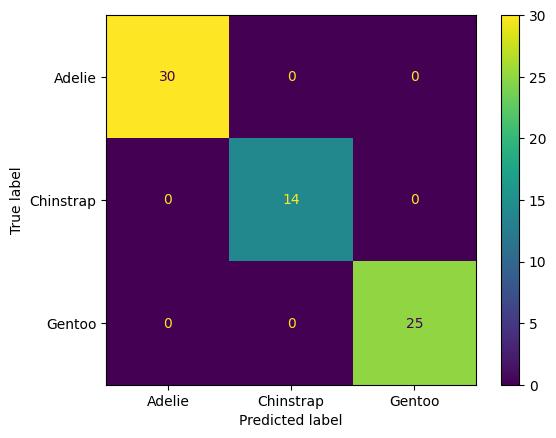

In [48]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

pipe_knn = Pipeline([("prepa", prepa), ("clf", KNeighborsClassifier())])

grille = {
    "clf__n_neighbors": [1, 3, 5, 7, 9, 11, 15, 21],
    "clf__weights": ["uniform", "distance"],
    "clf__metric": ["euclidean", "manhattan"],
}
# "clf__" = l'hyperparamètre de l'étape nommée "clf" dans le pipeline

recherche = GridSearchCV(pipe_knn, grille, cv=cv, scoring="f1_macro", n_jobs=-1)
recherche.fit(X_train, y_train)

print(recherche.best_params_)
print(round(recherche.best_score_, 3))

# Évaluation finale : on touche au test UNE seule fois
modele_final = recherche.best_estimator_
y_pred = modele_final.predict(X_test)
print(classification_report(y_test, y_pred, digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()